# H01: one raw neuron, from mesh to exported branches and spines

This example processes a **whole raw single-neuron mesh** through the supported NEURD API. It measures loading, segmentation and export, reports the resulting geometry, and saves a figure and a machine-readable run summary.

The reference input is `neuron_2530864375.off` from H01: **253,307 vertices and 507,737 faces**. The mesh is supplied locally; it is not embedded in this repository. The profile uses H01 parameters, detected spines, 12 SDF rays (`fast`), and refinement disabled. Detected spines are algorithm outputs; this notebook does not assess anatomical accuracy.

Use the [validated installation profile](../docs/INSTALLATION.md) and select its Python environment as the notebook kernel. Provide your mesh through `NEURD_EXAMPLE_MESH` or edit `MESH_PATH` below. Start a **fresh kernel** with `PYTHONHASHSEED=0`; numeric thread limits are set to one before importing NEURD. Set `NEURD_EXAMPLE_CPU` to an allowed Linux CPU to reproduce CPU affinity; otherwise the notebook retains your current affinity. The supporting `_single_neuron_example.py` file must remain beside the notebook.


In [1]:
from contextlib import redirect_stdout, redirect_stderr
from datetime import datetime, timezone
import json
import os
from pathlib import Path
import random
import sys
import tempfile

for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[name] = "1"
os.environ["NUMBA_NUM_THREADS"] = "1"

# Optional Linux CPU affinity for a comparable, controlled single-CPU run.
requested_cpu = os.environ.get("NEURD_EXAMPLE_CPU")
if requested_cpu is not None:
    if not hasattr(os, "sched_setaffinity"):
        raise RuntimeError("NEURD_EXAMPLE_CPU requires Linux CPU affinity support.")
    cpu = int(requested_cpu)
    if cpu not in os.sched_getaffinity(0):
        raise ValueError("Requested NEURD_EXAMPLE_CPU is outside the process CPU affinity.")
    os.sched_setaffinity(0, {cpu})

MESH_PATH = Path(os.environ.get("NEURD_EXAMPLE_MESH", "neuron_2530864375.off")).expanduser().resolve()
SEGMENT_ID = 2530864375
SEED = 0
REFERENCE_SHA256 = "ed914a7b70f370300b6ece631de9b1420eb5f0f876f01fb97f775ef63e203c3e"
EXPECTED_SHA256 = REFERENCE_SHA256 if MESH_PATH.name == "neuron_2530864375.off" else None

EXAMPLE_DIR = next(path for path in (Path.cwd(), Path.cwd() / "examples", Path.cwd().parent / "examples")
                   if (path / "_single_neuron_example.py").is_file())
sys.path.insert(0, str(EXAMPLE_DIR))
from _single_neuron_example import (
    RunMeasurements, environment_report, geometry_metrics, plot_geometry, sha256, working_directory,
)

if not MESH_PATH.is_file():
    raise FileNotFoundError("Set NEURD_EXAMPLE_MESH to an existing raw H01 mesh, or edit MESH_PATH.")
input_sha256 = sha256(MESH_PATH)
if EXPECTED_SHA256 is not None and input_sha256 != EXPECTED_SHA256:
    raise ValueError("The named reference mesh has a different SHA256; check the input file.")
if "neurd" in sys.modules:
    raise RuntimeError("Restart the kernel to measure a fresh NEURD import.")
preloaded_science_modules = [name for name in ("numpy", "scipy", "trimesh", "open3d") if name in sys.modules]

# An explicit output path must be new. The default creates a unique temporary run directory.
requested_output = os.environ.get("NEURD_EXAMPLE_OUTPUT")
if requested_output:
    OUTPUT_ROOT = Path(requested_output).expanduser().resolve()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=False)
else:
    OUTPUT_ROOT = Path(tempfile.mkdtemp(prefix="neurd-example-"))
# A new JIT cache makes this notebook observation include first-run compilation.
os.environ["NUMBA_CACHE_DIR"] = str(OUTPUT_ROOT / "numba_cache")
WORK_ROOT = OUTPUT_ROOT / "_work"
WORK_ROOT.mkdir()
print(f"Input: {MESH_PATH.name}; SHA256: {input_sha256}")
print("A new run directory is available as OUTPUT_ROOT; existing exports are never overwritten.")


Input: neuron_2530864375.off; SHA256: ed914a7b70f370300b6ece631de9b1420eb5f0f876f01fb97f775ef63e203c3e
A new run directory is available as OUTPUT_ROOT; existing exports are never overwritten.


## Import and configuration

`import neurd` comes before the mesh and skeleton providers so its compatibility and performance patches are installed. The import timing covers the public API and the analysis imports in this cell; Jupyter startup and the measurement helper are outside that timing. Full package/source and native-module fingerprints are saved in `run_summary.json`.


In [2]:
measurements = RunMeasurements(interval=0.05)
with measurements.stage("import"):
    import neurd
    failed_patches = [name for name, value in neurd.PATCH_STATUS.items() if value is False]
    if failed_patches:
        raise RuntimeError(f"NEURD patches failed: {failed_patches}. Check the installation before processing.")
    from neurd.mesh_io import load_mesh
    from neurd.run_config import RunConfig
    from neurd.segmentation_pipeline import segmentation_pipeline
    from neurd.neuron_export import save_segmentation
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

config = RunConfig(dataset="h01", calculate_spines=True, refinement="off", sdf_profile="fast")
environment = environment_report(neurd, config)
random.seed(SEED)
np.random.seed(SEED)
print("Configuration:", config.as_dict())
print(f"Python {environment['python']}; NEURD source digest: {environment['neurd_source_digest'][:16]}")
print("CPU affinity:", environment["cpu_affinity"])
versions = {name: environment["packages"].get(name) for name in
            ("numpy", "scipy", "trimesh", "open3d", "meshparty", "mesh-processing-tools")}
display(pd.Series(versions, name="version").to_frame())


Configuration: {'dataset': 'h01', 'calculate_spines': True, 'refinement': 'off', 'sdf_profile': 'fast', 'sdf_rays': 12, 'refinement_config': None}
Python 3.12.13; NEURD source digest: aa74176883df62b4
CPU affinity: [2]


,version
numpy,2.4.6
scipy,1.17.1
trimesh,4.12.2
open3d,0.19.0
meshparty,2.0.3
mesh-processing-tools,1.0.4


## Load and process the entire mesh

No input decimation or pre-exported branch is used. The segmentation call includes soma extraction, limb and branch decomposition, skeletonization, widths and spine detection. Intermediate mesh operations write into the run's `_work` directory. Progress output is retained in `processing.log`.


In [3]:
with measurements.stage("load"):
    mesh = load_mesh(MESH_PATH)
if input_sha256 == REFERENCE_SHA256:
    assert (len(mesh.vertices), len(mesh.faces)) == (253307, 507737)
display(pd.Series({"vertices": len(mesh.vertices), "faces": len(mesh.faces)}, name="input").to_frame())


,input
vertices,253307
faces,507737


In [4]:
try:
    with working_directory(WORK_ROOT), (OUTPUT_ROOT / "processing.log").open("w") as log:
        with redirect_stdout(log), redirect_stderr(log), measurements.stage("segmentation"):
            neuron = segmentation_pipeline(mesh, segment_id=SEGMENT_ID, config=config)
except Exception:
    measurements.close()
    raise
print("Whole-neuron segmentation completed.")


Whole-neuron segmentation completed.


## Export and inspect the result

The library exporter saves soma, limb, branch and spine meshes, skeleton arrays, connectivity and face-provenance records. It writes directly to this new directory. For resumable datasets and worker limits, use the batch runners described in the README.


In [5]:
EXPORT_ROOT = OUTPUT_ROOT / "segmentation"
try:
    with working_directory(WORK_ROOT), (OUTPUT_ROOT / "processing.log").open("a") as log:
        with redirect_stdout(log), redirect_stderr(log), measurements.stage("export"):
            save_segmentation(neuron, EXPORT_ROOT)
finally:
    measurements.close()

measurement_report = measurements.report()
geometry, branch_rows = geometry_metrics(neuron)
exported_files = sorted(path for path in EXPORT_ROOT.rglob("*") if path.is_file())
print(f"Export: segmentation/ ({len(exported_files)} files)")
display(pd.Series(geometry, name="result").to_frame())
branches = pd.DataFrame(branch_rows)
if not branches.empty:
    display(branches.loc[branches["detected_spines"] > 0].reset_index(drop=True))


Export: segmentation/ (218 files)


,result
n_somas,1.00000
soma_mesh_faces,244286.00000
n_limbs,5.00000
n_branches_total,28.00000
branch_mesh_faces_total,291761.00000
skeleton_length_total_um,367.20816
n_spines_total,18.00000
branches_with_spines,6.00000
spine_mesh_faces_total,8145.00000
positive_spine_volumes,18.00000


,limb,branch,mesh_faces,skeleton_length_um,detected_spines,spine_mesh_faces,positive_spine_volumes,spine_volume_um3
0,0,1,78842,100.011880,5,4171,5,2.275183
1,0,11,24238,27.452808,7,1877,7,2.025466
2,1,0,33109,63.857273,1,473,1,0.108164
3,2,0,37269,30.826672,3,790,3,0.402347
4,3,0,4877,9.598094,1,445,1,0.114469
5,3,2,6872,9.127243,1,389,1,0.174432


## Time and memory

The stage durations measure the calls shown above, without profiling or forced garbage collection. **Kernel lifetime peak RSS includes Jupyter startup.** Sampled kernel RSS and sampled kernel-plus-children RSS cover the window from import through export. The latter sums resident memory across live processes, counts shared pages in each process, and can miss child peaks shorter than the 50 ms sampling interval. These are RSS measurements, not Python allocation measurements.

The geometry tables and rendering below are produced after sampling stops. A new per-run Numba cache includes first-use compilation. This is one notebook observation; use the separate controlled benchmark for before/after comparisons.


In [6]:
stages = pd.DataFrame(measurement_report["stages"])
stages["kernel_peak_GiB_sampled"] = stages.pop("sampled_process_peak_bytes") / 1024**3
stages["kernel_and_children_peak_GiB_sampled"] = stages.pop("sampled_process_and_children_peak_bytes") / 1024**3
display(stages.round(3))
display(pd.Series({
    "load + segmentation + export (s)": measurement_report["load_segmentation_export_seconds"],
    "kernel lifetime peak RSS (GiB)": measurement_report["process_lifetime_peak_bytes"] / 1024**3,
    "sampled kernel + children peak RSS (GiB)": measurement_report["sampled_process_and_children_peak_bytes"] / 1024**3,
}, name="measurement").round(3).to_frame())


,stage,seconds,kernel_peak_GiB_sampled,kernel_and_children_peak_GiB_sampled
0,import,5.009,0.468,0.468
1,load,0.917,0.488,0.488
2,segmentation,210.227,1.287,1.344
3,export,1.315,1.287,1.287


,measurement
load + segmentation + export (s),212.459
kernel lifetime peak RSS (GiB),1.287
sampled kernel + children peak RSS (GiB),1.344


## Geometry preview

The left panel shows the full skeleton, colored by limb, and the soma in an XY projection. The right panel shows the largest detected spine mesh (red) with a crop of its branch surface (gray). Coordinates are converted from nanometres to micrometres. Rendering samples soma and shaft faces for display only; processing and export use the complete meshes.


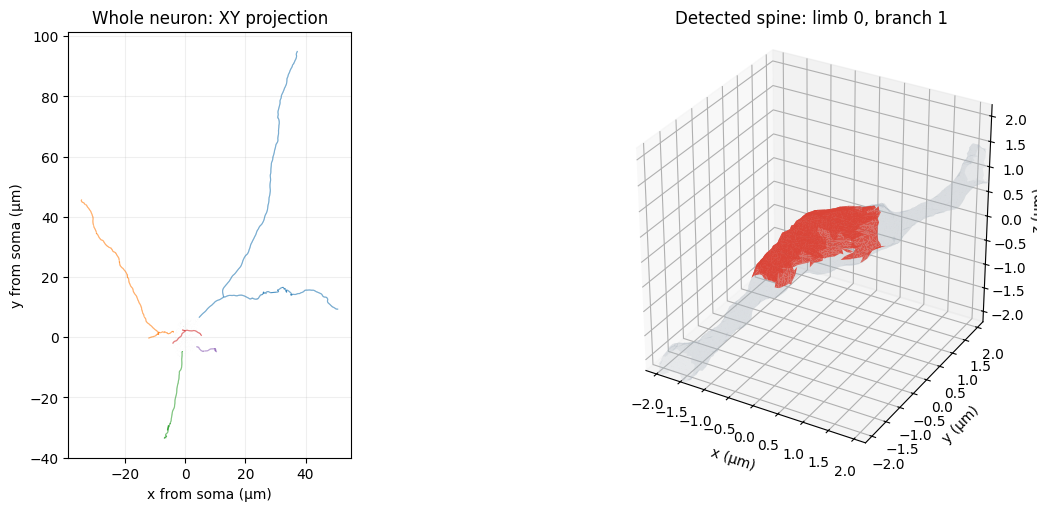

In [7]:
figure = plot_geometry(neuron)
figure.savefig(OUTPUT_ROOT / "neuron_preview.png", dpi=180)
figure.savefig(OUTPUT_ROOT / "neuron_preview.pdf")
plt.show()


## Save this observation and view the controlled comparison

The summary identifies the input by basename and SHA256 and retains the effective configuration, package versions, source/native fingerprints, measured stages and geometry counts. It does not store local absolute input or package paths. The CSV contains the raw RSS samples. The accompanying controlled benchmark, when present, is a separate experiment with its own scope and equivalence checks.


In [8]:
run_summary = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "input": {"filename": MESH_PATH.name, "sha256": input_sha256, "bytes": MESH_PATH.stat().st_size,
              "vertices": len(mesh.vertices), "faces": len(mesh.faces)},
    "segment_id": SEGMENT_ID, "seed": SEED, "configuration": config.as_dict(),
    "environment": environment, "preloaded_science_modules": preloaded_science_modules,
    "jit_cache_policy": "new cache per notebook run; first-use compilation included",
    "geometry": geometry, "measurement": measurement_report,
    "export": {"directory": "segmentation", "files": len(exported_files)},
}
(OUTPUT_ROOT / "run_summary.json").write_text(json.dumps(run_summary, indent=2) + "\n")
pd.DataFrame(measurements.samples, columns=["seconds", "kernel_rss_bytes", "kernel_and_children_rss_bytes"]).to_csv(
    OUTPUT_ROOT / "rss_samples.csv", index=False,
)
print("Saved: run_summary.json, rss_samples.csv, processing.log, neuron_preview.png and neuron_preview.pdf.")

comparison_path = EXAMPLE_DIR / "h01_benchmark_summary.json"
if comparison_path.is_file():
    comparison = json.loads(comparison_path.read_text())
    print(comparison["scope"])
    print(comparison["method"])
    display(pd.DataFrame(comparison["results"]))
    print("Equivalence:", comparison["equivalence"])
else:
    print("No controlled benchmark summary accompanies this checkout.")


Saved: run_summary.json, rss_samples.csv, processing.log, neuron_preview.png and neuron_preview.pdf.
Optimizations and cleanup after the integration candidate, with identical scientific dependencies and compiled native providers; excludes older original-framework gains.
Three alternating pairs of fresh processes after one excluded setup per variant; persistent separate Numba caches, CPU 2, one numerical thread, seed 0. Core total is load + construction + each variant's export, excluding import and QC.


,variant,runs,commit,load_seconds_median,segmentation_seconds_median,export_seconds_median,total_seconds_median,total_seconds_range,import_setup_seconds_median,peak_process_rss_gib_median,peak_process_rss_gib_range,peak_tree_rss_gib_median,peak_tree_rss_gib_range
0,baseline,3,e2fb110263d1707089f44dbdc08d6eb9d9fc6521,2.135293,210.152775,1.203425,213.383447,"[207.3058825080043, 221.65290394099793]",5.378557,1.139271,"[1.1286506652832031, 1.1542816162109375]",1.302330,"[1.2919120788574219, 1.3103446960449219]"
1,candidate,3,4b7fa78d993444530444b3c440d0e451823a5b58,1.397090,224.297902,1.433967,227.158676,"[219.45552698699976, 228.36663196600057]",5.420419,1.154793,"[1.153045654296875, 1.169830322265625]",1.331322,"[1.330718994140625, 1.3322410583496094]"


Equivalence: All eight runs preserve ordered in-memory meshes, skeletons, spine masks, widths and scalar volumes, plus common saved scientific values: one soma, five limbs, 28 branches and 18 spines / 8,145 spine faces.
